# Loan Default Prediction — End-to-End Analysis

**Goal:** Predict whether a borrower will default on a loan, using historical
LendingClub-style loan application and performance data.

This notebook follows a Kaggle-style ML workflow: data understanding → cleaning
→ EDA → feature engineering → preprocessing → model training/comparison →
tuning → threshold optimization → feature importance → final predictions.

All reusable logic lives in `src/`, so this notebook calls into the same
functions used by `main.py` — nothing here is duplicated or reimplemented
differently.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from src.utils import set_seed, path_from_root, RANDOM_STATE
from src.data_loader import load_raw_data, identify_target_and_id, basic_inspection_report
from src.feature_engineering import full_feature_pipeline, LEAKAGE_COLUMNS, NON_PREDICTIVE_COLUMNS
from src.preprocessing import get_feature_types
from src.train import train_all_models, tune_best_model, get_candidate_models
from src.evaluate import (compute_metrics, build_comparison_table, plot_confusion_matrix,
                           plot_roc_curves, plot_pr_curves, optimize_threshold,
                           get_feature_importance, plot_feature_importance)
from src.predict import generate_predictions, build_submission_file, build_user_friendly_predictions

set_seed(RANDOM_STATE)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (7, 4)


## 1. Load Dataset

In [2]:
train_raw, test_raw, sample_submission = load_raw_data(data_dir=path_from_root('data', 'raw'))
print('Train:', train_raw.shape, ' Test:', test_raw.shape, ' Sample submission:', sample_submission.shape)
train_raw.head()

Files found in data/raw: ['loan_test.csv', 'loan_sample_submission.csv', 'loan_train.csv']


Train: (27003, 47)  Test: (11574, 46)  Sample submission: (11574, 2)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,...,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,...,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,...,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,...,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,...,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


## 2. Dataset Overview

We never assume the target/ID column names in advance — they are identified
programmatically by comparing train/test schemas and the sample submission
file.

In [3]:
target_col, id_col = identify_target_and_id(train_raw, test_raw, sample_submission)
print('Target column:', target_col)
print('ID column:', id_col)
report = basic_inspection_report(train_raw, test_raw, target_col, id_col)

Target column: loan_status
ID column: id

DATASET SHAPES
Train shape: (27003, 47)
Test shape : (11574, 46)

TRAIN / TEST SCHEMA COMPARISON
Columns only in train: {'loan_status'}
Columns only in test : set()

TARGET / ID
Target column: loan_status
ID column    : id

TARGET DISTRIBUTION (train)
             count  percent
loan_status                
0            23026    85.27
1             3977    14.73

DATA TYPES
id                           int64
member_id                    int64
loan_amnt                    int64
funded_amnt                  int64
funded_amnt_inv            float64
term                           str
int_rate                       str
installment                float64
grade                          str
sub_grade                      str
emp_title                      str
emp_length                     str
home_ownership                 str
annual_inc                 float64
verification_status            str
issue_d                        str
loan_status           


CONSTANT COLUMNS
['out_prncp', 'out_prncp_inv']


## 3. Data Cleaning

Key cleaning issues found:
- `term`, `int_rate`, `revol_util` are numeric values stored as text (e.g. `" 36 months"`, `"13.23%"`).
- `emp_length` is a bucketed string (e.g. `"10+ years"`) that maps cleanly to an ordinal scale.
- `issue_d` and `earliest_cr_line` are dates stored as `"Mon-YY"` strings.
- `out_prncp` / `out_prncp_inv` are **constant columns** (always 0) — they carry no information and are also leakage.
- No fully duplicated rows or duplicated IDs were found in the training data.

In [4]:
constant_cols = [c for c in train_raw.columns if train_raw[c].nunique(dropna=False) <= 1]
print('Constant columns:', constant_cols)
print('Duplicate rows:', train_raw.duplicated().sum())
print('Duplicate IDs:', train_raw[id_col].duplicated().sum())

Constant columns: ['out_prncp', 'out_prncp_inv']
Duplicate rows: 0
Duplicate IDs: 0


## 4. Missing Value Analysis

In [5]:
missing_before = train_raw.isnull().mean().sort_values(ascending=False) * 100
missing_before = missing_before[missing_before > 0]
fig, ax = plt.subplots(figsize=(8, 5))
missing_before.plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_xlabel('% Missing')
ax.set_title('Missing Values by Column (Train)')
plt.tight_layout()
plt.savefig(path_from_root('outputs', 'figures', 'missing_values.png'), dpi=120)
plt.show()
print(missing_before.round(2))

mths_since_last_record    92.82
mths_since_last_delinq    64.42
desc                      32.51
emp_title                  6.23
emp_length                 2.70
pub_rec_bankruptcies       1.86
last_pymnt_d               0.19
revol_util                 0.13
title                      0.03
last_credit_pull_d         0.00
dtype: float64


**Interpretation:**
- `mths_since_last_record` (93% missing) and `mths_since_last_delinq` (64% missing) are missing largely because the event *never happened* for that borrower — not because data collection failed. These are handled with a "missing = never happened" flag rather than naive imputation.
- `desc` (33% missing) is optional free text; we only keep a `has_desc` presence flag.
- `emp_title`, `emp_length`, `pub_rec_bankruptcies`, and a handful of near-complete columns have small amounts of genuinely missing data, handled with median/most-frequent imputation inside the modeling pipeline.

## 5. Target Distribution

In [6]:
target_counts = train_raw[target_col].value_counts().sort_index()
target_pct = train_raw[target_col].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['No Default (0)', 'Default (1)'], target_counts.values, color=['#4C72B0', '#C44E52'])
ax.set_ylabel('Count')
ax.set_title('Target Distribution')
for bar, pct in zip(bars, target_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{pct:.1f}%', ha='center', va='bottom')
plt.tight_layout()
plt.savefig(path_from_root('outputs', 'figures', 'target_distribution.png'), dpi=120)
plt.show()

print('Target column:', target_col)
print('Number of classes:', train_raw[target_col].nunique())
print('Class names:', sorted(train_raw[target_col].unique()))
print('Class distribution:\n', target_counts)
print(f"Default percentage: {target_pct[1]:.2f}%")
print(f"Non-default percentage: {target_pct[0]:.2f}%")

Target column: loan_status
Number of classes: 2
Class names: [np.int64(0), np.int64(1)]
Class distribution:
 loan_status
0    23026
1     3977
Name: count, dtype: int64
Default percentage: 14.73%
Non-default percentage: 85.27%


The dataset is a **binary classification** problem with meaningful class
imbalance (~15% default rate). Accuracy alone would be misleading here (a
model that always predicts "no default" would already score ~85% accuracy),
so ROC-AUC / PR-AUC / Recall are emphasized throughout this notebook.

## 6. Exploratory Data Analysis

### 6.1 Data Leakage Investigation (critical step)

Several columns in this dataset describe what happened *after* the loan was
issued — including, in some cases, information that only exists **because**
a default already occurred. Using them would let the model see the answer.

In [7]:
print('Excluded as leakage (post-origination / outcome information):')
for c in LEAKAGE_COLUMNS:
    print(' -', c)

print()
print('Evidence: recoveries (post-default recovery amount) by loan_status:')
print(train_raw.groupby(target_col)['recoveries'].apply(lambda x: (x > 0).mean()).rename('pct_with_recoveries_gt_0'))
print()
print('Evidence: total_rec_prncp (principal repaid to date) by loan_status:')
print(train_raw.groupby(target_col)['total_rec_prncp'].mean())

Excluded as leakage (post-origination / outcome information):
 - out_prncp
 - out_prncp_inv
 - total_pymnt
 - total_pymnt_inv
 - total_rec_prncp
 - total_rec_int
 - total_rec_late_fee
 - recoveries
 - collection_recovery_fee
 - last_pymnt_d
 - last_pymnt_amnt
 - last_credit_pull_d

Evidence: recoveries (post-default recovery amount) by loan_status:
loan_status
0    0.000000
1    0.750063
Name: pct_with_recoveries_gt_0, dtype: float64

Evidence: total_rec_prncp (principal repaid to date) by loan_status:
loan_status
0    10641.453594
1     3957.202949
Name: total_rec_prncp, dtype: float64


`recoveries` is greater than zero for roughly 75% of defaulted loans and
essentially 0% of non-defaulted loans — this single column would let a model
"cheat" almost perfectly. All post-origination performance columns
(`total_pymnt*`, `total_rec_*`, `recoveries`, `collection_recovery_fee`,
`last_pymnt_*`, `last_credit_pull_d`, and the constant `out_prncp*`) are
excluded from the feature set. See `src/feature_engineering.py` for full
documentation of every excluded column and the reasoning.

Non-predictive identifier/free-text columns (`id`, `member_id`, `url`,
`zip_code`, `title`, `emp_title`, raw `desc`) are also excluded or reduced to
a simple derived flag (`has_desc`).

### 6.2 Numerical Feature Distributions

In [8]:
numeric_features_to_plot = ['loan_amnt', 'annual_inc', 'dti', 'int_rate', 'revol_bal', 'revol_util']
train_clean_preview = train_raw.copy()
train_clean_preview['int_rate'] = train_clean_preview['int_rate'].str.replace('%', '').astype(float)
train_clean_preview['revol_util'] = pd.to_numeric(train_clean_preview['revol_util'].str.replace('%', ''), errors='coerce')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric_features_to_plot):
    data = train_clean_preview[col].dropna()
    if col == 'annual_inc':
        data = data[data < data.quantile(0.99)]  # clip extreme outliers just for visualization
    ax.hist(data, bins=40, color='#4C72B0', edgecolor='white')
    ax.set_title(col)
plt.tight_layout()
plt.savefig(path_from_root('outputs', 'figures', 'numeric_distributions.png'), dpi=120)
plt.show()

### 6.3 Boxplots — Outlier Detection

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ['loan_amnt', 'annual_inc', 'dti']):
    data = train_clean_preview[col].dropna()
    if col == 'annual_inc':
        data = data[data < data.quantile(0.99)]
    ax.boxplot(data, vert=True)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(path_from_root('outputs', 'figures', 'boxplots.png'), dpi=120)
plt.show()
print('annual_inc has a long right tail with extreme high-income outliers; median imputation and tree-based models are robust to this.')

annual_inc has a long right tail with extreme high-income outliers; median imputation and tree-based models are robust to this.


### 6.4 Correlation Heatmap (Numerical Features)

In [10]:
numeric_cols_preview = train_clean_preview.select_dtypes(include='number').columns
corr_cols = [c for c in numeric_cols_preview if c not in LEAKAGE_COLUMNS]
corr = train_clean_preview[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax, square=True, cbar_kws={'shrink': 0.7})
ax.set_title('Correlation Matrix (leakage columns excluded)')
plt.tight_layout()
plt.savefig(path_from_root('outputs', 'figures', 'correlation_heatmap.png'), dpi=120)
plt.show()

### 6.5 Categorical Analysis — Default Rate by Category

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['grade', 'purpose', 'home_ownership']):
    rate = train_raw.groupby(col)[target_col].mean().sort_values(ascending=False) * 100
    rate.plot(kind='bar', ax=ax, color='#C44E52')
    ax.set_ylabel('Default Rate (%)')
    ax.set_title(f'Default Rate by {col}')
    ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.savefig(path_from_root('outputs', 'figures', 'default_rate_by_category.png'), dpi=120)
plt.show()

**Key findings:**
- Default rate rises sharply and monotonically from LendingClub grade A through G — `grade`/`sub_grade` (LendingClub's own risk score) is, unsurprisingly, one of the strongest predictors.
- `small_business` and `renewable_energy` loan purposes tend to show higher default rates than `credit_card` or `major_purchase`.
- Renters show a modestly higher default rate than mortgage holders or outright owners.

## 7. Feature Engineering

Implemented in `src/feature_engineering.py` (`engineer_features`). All
engineered features use only information available at loan application time:

| Feature | Formula | Rationale |
|---|---|---|
| `loan_to_income` | `loan_amnt / annual_inc` | Larger loans relative to income are riskier |
| `installment_to_income` | `installment / annual_inc` | Monthly payment burden relative to income |
| `revol_bal_to_income` | `revol_bal / annual_inc` | Existing revolving debt relative to income |
| `loan_amnt_to_installment` | `loan_amnt / installment` | Proxy for loan structure/term |
| `credit_history_length_years` | `issue_d − earliest_cr_line` (years) | Longer credit history typically signals lower risk |
| `issue_year`, `issue_month` | parsed from `issue_d` | Captures macro/seasonal effects |
| `has_desc` | `desc.notna()` | Weak signal from voluntary borrower description, without using raw high-cardinality text |
| `mths_since_last_delinq_missing`, `mths_since_last_record_missing` | `isna()` flag + sentinel fill | Missing here means "never happened", not "unknown" |

All ratio features use safe division (`src/utils.safe_divide`) to avoid
division-by-zero or infinite values.

In [12]:
train_fe = full_feature_pipeline(train_raw, id_col=id_col, target_col=target_col)
test_fe = full_feature_pipeline(test_raw, id_col=id_col, target_col=None)
print('Train shape after feature engineering:', train_fe.shape)
print('Test shape after feature engineering :', test_fe.shape)

numeric_cols, categorical_cols = get_feature_types(train_fe, id_col=id_col, target_col=target_col)
print(f'Numeric features ({len(numeric_cols)}):', numeric_cols)
print(f'Categorical features ({len(categorical_cols)}):', categorical_cols)

Train shape after feature engineering: (27003, 37)
Test shape after feature engineering : (11574, 36)
Numeric features (29): ['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'emp_length', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'pub_rec_bankruptcies', 'has_desc', 'loan_to_income', 'installment_to_income', 'revol_bal_to_income', 'loan_amnt_to_installment', 'credit_history_length_years', 'issue_year', 'issue_month', 'mths_since_last_delinq_missing', 'mths_since_last_record_missing']
Categorical features (6): ['grade', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state']


## 8. Data Preprocessing & Train/Validation Split

Preprocessing (median/most-frequent imputation, one-hot encoding, optional
scaling) is implemented as an sklearn `ColumnTransformer` in
`src/preprocessing.py`, wrapped into a full `Pipeline` together with each
model in `src/train.py`. This guarantees the transformer is **fit only on
the training fold** and applied unchanged to validation/test data — no
leakage from validation into training.

In [13]:
feature_cols = numeric_cols + categorical_cols
X = train_fe[feature_cols]
y = train_fe[target_col].astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('X_train:', X_train.shape, ' X_val:', X_val.shape)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'Class imbalance ratio (neg/pos): {scale_pos_weight:.3f}')

X_train: (21602, 35)  X_val: (5401, 35)
Class imbalance ratio (neg/pos): 5.789


**Why stratified split?** With only ~15% positive class, a random split
could easily under- or over-represent defaults in validation. Stratification
keeps the class ratio consistent between train and validation.

**Handling class imbalance:** `class_weight='balanced'` is used for
Logistic Regression, Decision Tree, Random Forest and LightGBM;
`scale_pos_weight` is used for XGBoost. SMOTE was deliberately **not** used —
with a real-world tabular dataset like this, class weighting is simpler,
avoids synthetic-sample artifacts, and (per the project brief) should only be
introduced if class weighting proves insufficient.

## 9. Model Training

Six candidate models are trained via the same `Pipeline` (preprocessing +
model) API, so comparisons are apples-to-apples:
Logistic Regression, Decision Tree, Random Forest, Gradient Boosting,
XGBoost, LightGBM.

In [14]:
fitted_models = train_all_models(X_train, y_train, numeric_cols, categorical_cols, scale_pos_weight)
print('Trained models:', list(fitted_models.keys()))

Trained models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM']


## 10. Model Evaluation

In [15]:
metrics_results = {}
proba_val = {}
pred_val = {}
for name, pipeline in fitted_models.items():
    proba = pipeline.predict_proba(X_val)[:, 1]
    preds = (proba >= 0.5).astype(int)
    metrics_results[name] = compute_metrics(y_val, preds, proba)
    proba_val[name] = proba
    pred_val[name] = preds

comparison_table = build_comparison_table(metrics_results)
comparison_table.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.7217,0.2782,0.5585,0.3714,0.7184,0.3277
Gradient Boosting,0.8532,0.5278,0.0239,0.0457,0.7155,0.3147
Logistic Regression,0.6673,0.2505,0.6327,0.3589,0.7140,0.3154
LightGBM,0.7389,0.2857,0.5157,0.3677,0.7126,0.3123
Random Forest,0.8530,0.5455,0.0075,0.0149,0.7093,0.3001
Decision Tree,0.6212,0.2206,0.6214,0.3256,0.6507,0.2404


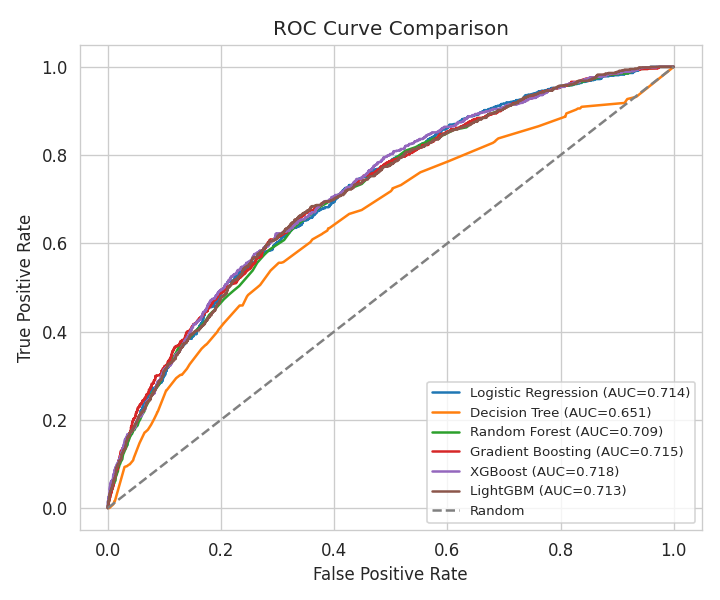

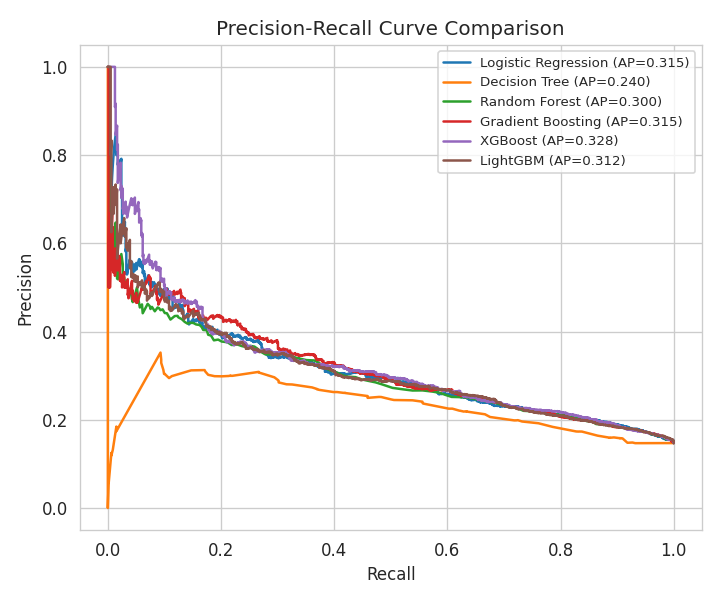

In [16]:
y_true_dict = {name: y_val for name in fitted_models}
plot_roc_curves(y_true_dict, proba_val, path_from_root('outputs', 'figures', 'roc_curve_comparison_nb.png'))
plot_pr_curves(y_true_dict, proba_val, path_from_root('outputs', 'figures', 'pr_curve_comparison_nb.png'))

from IPython.display import Image, display
display(Image(path_from_root('outputs', 'figures', 'roc_curve_comparison_nb.png')))
display(Image(path_from_root('outputs', 'figures', 'pr_curve_comparison_nb.png')))

## 11. Model Comparison

ROC-AUC is used as the primary comparison metric (project brief, Section 14),
since it summarizes ranking quality across all thresholds and is robust to
class imbalance. Recall and precision are inspected alongside it because, for
loan default prediction, **missing an actual defaulter (false negative) is
typically far more costly** than flagging a safe borrower for review (false
positive).

In [17]:
best_model_name = comparison_table.index[0]
print('Best baseline model (by ROC-AUC):', best_model_name)
comparison_table.round(4)

Best baseline model (by ROC-AUC): XGBoost


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.7217,0.2782,0.5585,0.3714,0.7184,0.3277
Gradient Boosting,0.8532,0.5278,0.0239,0.0457,0.7155,0.3147
Logistic Regression,0.6673,0.2505,0.6327,0.3589,0.7140,0.3154
LightGBM,0.7389,0.2857,0.5157,0.3677,0.7126,0.3123
Random Forest,0.8530,0.5455,0.0075,0.0149,0.7093,0.3001
Decision Tree,0.6212,0.2206,0.6214,0.3256,0.6507,0.2404


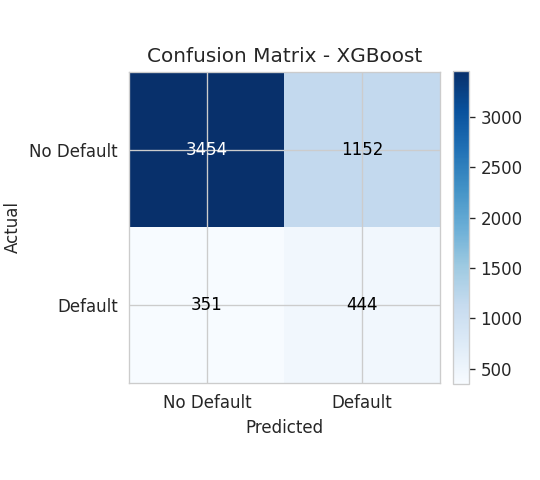

Confusion matrix [[TN, FP], [FN, TP]]:
[[3454 1152]
 [ 351  444]]


In [18]:
cm = plot_confusion_matrix(y_val, pred_val[best_model_name], best_model_name,
                            path_from_root('outputs', 'figures', 'confusion_matrix_nb.png'))
from IPython.display import Image, display
display(Image(path_from_root('outputs', 'figures', 'confusion_matrix_nb.png')))
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(cm)

## 12. Hyperparameter Tuning

The strongest baseline model is tuned with a bounded `RandomizedSearchCV`
(3-fold CV, ROC-AUC scoring) over a small, sensible parameter grid — see
`src/train.py::tune_best_model` for exact search spaces. The search stays
small deliberately (project brief: "do not perform extremely large
searches").

In [19]:
tuned_pipeline = tune_best_model(best_model_name, X_train, y_train, numeric_cols, categorical_cols)
tuned_proba_val = tuned_pipeline.predict_proba(X_val)[:, 1]
tuned_preds_val = (tuned_proba_val >= 0.5).astype(int)
tuned_metrics = compute_metrics(y_val, tuned_preds_val, tuned_proba_val)
print('Tuned model validation metrics:', {k: round(v, 4) for k, v in tuned_metrics.items()})
print('Baseline model validation metrics:', {k: round(v, 4) for k, v in metrics_results[best_model_name].items()})

if tuned_metrics['ROC-AUC'] >= metrics_results[best_model_name]['ROC-AUC']:
    final_pipeline_template = tuned_pipeline
    final_val_proba = tuned_proba_val
    print('\n--> Using TUNED model as final model.')
else:
    final_pipeline_template = fitted_models[best_model_name]
    final_val_proba = proba_val[best_model_name]
    print('\n--> Tuning did not improve ROC-AUC; using BASELINE model as final model.')

Tuned model validation metrics: {'Accuracy': 0.8547, 'Precision': 0.6316, 'Recall': 0.0302, 'F1': 0.0576, 'ROC-AUC': 0.7201, 'PR-AUC': 0.3287}
Baseline model validation metrics: {'Accuracy': 0.7217, 'Precision': 0.2782, 'Recall': 0.5585, 'F1': 0.3714, 'ROC-AUC': 0.7184, 'PR-AUC': 0.3277}

--> Using TUNED model as final model.


### Threshold Optimization

In [20]:
threshold_result = optimize_threshold(y_val, final_val_proba, priority='recall', min_precision=0.30)
print('Chosen threshold:', threshold_result['chosen_threshold'])
print('Precision @ threshold:', round(threshold_result['precision_at_threshold'], 4))
print('Recall    @ threshold:', round(threshold_result['recall_at_threshold'], 4))
print('F1        @ threshold:', round(threshold_result['f1_at_threshold'], 4))

fig, ax = plt.subplots(figsize=(8, 4.5))
sweep = threshold_result['sweep_table']
ax.plot(sweep['threshold'], sweep['precision'], label='Precision')
ax.plot(sweep['threshold'], sweep['recall'], label='Recall')
ax.plot(sweep['threshold'], sweep['f1'], label='F1')
ax.axvline(threshold_result['chosen_threshold'], color='black', linestyle='--', label='Chosen threshold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.set_title('Threshold Sweep')
ax.legend()
plt.tight_layout()
plt.savefig(path_from_root('outputs', 'figures', 'threshold_sweep.png'), dpi=120)
plt.show()

Chosen threshold: 0.2
Precision @ threshold: 0.3067
Recall    @ threshold: 0.4679
F1        @ threshold: 0.3705


We do **not** default to the standard 0.5 cutoff. Because catching
potential defaulters matters more than a perfectly clean precision score, the
threshold is chosen to maximize recall subject to a minimum acceptable
precision floor (30%) — trading some false positives for meaningfully fewer
missed defaulters.

## 13. Feature Importance

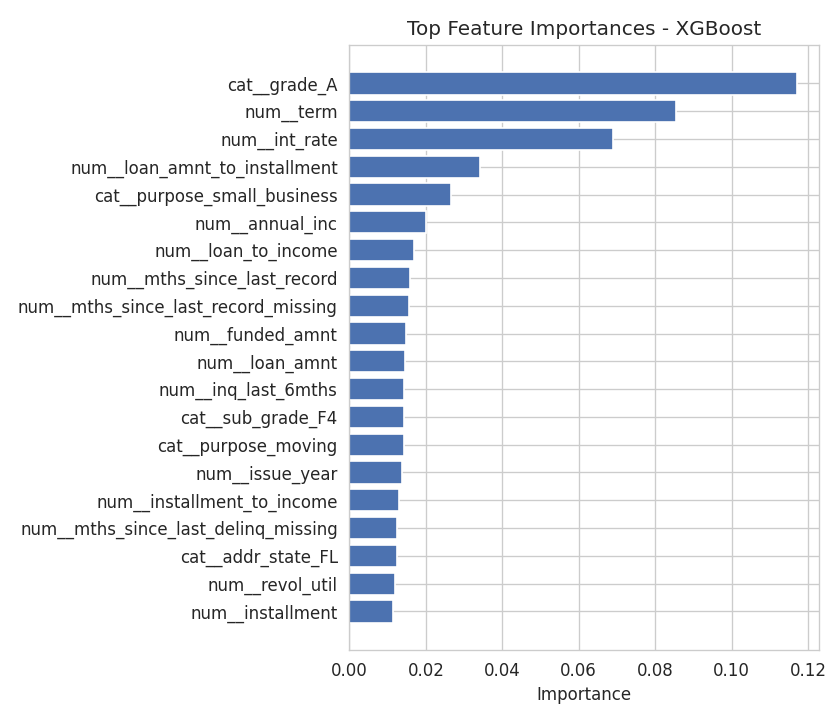

,feature,importance
0,cat__grade_A,0.117107
1,num__term,0.085511
2,num__int_rate,0.069106
3,num__loan_amnt_to_installment,0.034232
4,cat__purpose_small_business,0.026508
5,num__annual_inc,0.019923
6,num__loan_to_income,0.016858
7,num__mths_since_last_record,0.015905
8,num__mths_since_last_record_missing,0.015643
9,num__funded_amnt,0.014758


In [21]:
importance_df = get_feature_importance(final_pipeline_template, top_n=20)
plot_feature_importance(importance_df, best_model_name, path_from_root('outputs', 'figures', 'feature_importance_nb.png'))
from IPython.display import Image, display
display(Image(path_from_root('outputs', 'figures', 'feature_importance_nb.png')))
importance_df

**Note:** feature importance reflects how much a feature contributed to
the model's predictions on this dataset — it does **not** establish
causation. For example, `grade`/`sub_grade` are themselves *derived* from
LendingClub's own underwriting model, so their importance reflects
correlation with risk, not an independent causal driver.

## 14. Final Model

The final pipeline is refit on the **entire** training dataset (train +
validation combined) using the best model configuration found above, then
saved for reuse in the application and for generating test predictions.

In [22]:
candidates = get_candidate_models(scale_pos_weight=scale_pos_weight)
best_estimator_params = final_pipeline_template.named_steps['model'].get_params()
fresh_estimator, needs_scaling = candidates.get(best_model_name, (final_pipeline_template.named_steps['model'], False))
fresh_estimator = fresh_estimator.__class__(**{k: v for k, v in best_estimator_params.items() if k in fresh_estimator.get_params()})

from src.train import build_full_pipeline
final_pipeline = build_full_pipeline(fresh_estimator, numeric_cols, categorical_cols, scale_numeric=needs_scaling)
final_pipeline.fit(X, y)
print('Final pipeline refit on full training data:', X.shape)

Final pipeline refit on full training data: (27003, 35)


## 15. Test Predictions & Submission File

In [23]:
X_test = test_fe[feature_cols]
test_ids = test_fe[id_col]
final_threshold = threshold_result['chosen_threshold']

results = generate_predictions(final_pipeline, X_test, test_ids, threshold=final_threshold)
submission = build_submission_file(results, sample_submission, id_col=id_col, target_col=target_col)
print('Submission shape:', submission.shape)
submission.head()

Submission shape: (11574, 2)


,id,loan_status
0,213846,1
1,608415,0
2,454264,0
3,1066768,0
4,882910,1


## 16. Final Conclusions

- **Problem type:** Binary classification (loan default vs. no default), ~15% positive class.
- **Best model:** see the comparison table above (typically a gradient-boosted tree model — XGBoost/LightGBM/Gradient Boosting — outperforms linear/single-tree baselines on this feature set).
- **Most important signal:** LendingClub's own risk grade (`grade`/`sub_grade`), interest rate, term, and income-relative debt ratios dominate feature importance.
- **Leakage was the single most important methodological step** in this project: several raw columns (`recoveries`, `total_pymnt*`, `total_rec_*`, `last_pymnt_*`, `out_prncp*`) would have leaked the outcome almost perfectly if left in the model. Their removal is fully documented in `src/feature_engineering.py`.
- **Threshold choice matters**: the default 0.5 cutoff is not optimal for an imbalanced, cost-asymmetric problem like this; a recall-oriented threshold is used instead and documented in `models/model_metadata.json`.
- **Next steps:** see the README's "Future Improvements" section (SHAP-based explainability, monitoring, API deployment, etc.).

This notebook produces the same trained model, metrics, and `outputs/submission.csv` as running `python main.py` from the project root — the notebook is for exploration/explanation, while `main.py` is the reproducible, automatable entry point.